# การตรวจจับธุรกรรมทุจริตทางการเงิน (Financial Fraud Detection)
## ด้วย 2-Stage Stacking GBDT Ensemble (XGBoost, LightGBM, CatBoost)

### ที่มาและแนวคิด
ในโจทย์นี้ เราต้องการทำนายว่าธุรกรรมแต่ละรายการใน `test.csv` เป็นการ **ทุจริต (`is_fraud = 1`)** หรือ **ปกติ (`is_fraud = 0`)** โดยเรียนรู้จาก log ธุรกรรมของลูกค้าประมาณ 2,500 ราย ในช่วงเวลา 90 วัน

จุดสำคัญและแนวทางการออกแบบโมเดล:
* **Class Imbalance:** มีธุรกรรมทุจริตเพียงประมาณ 2.04% และประเมินผลด้วย **F1-score ของคลาส 1** (ส่งคำตอบเป็น `0` หรือ `1`)
* **แก้ปัญหา Gradient Starvation ด้วย 2-Stage Stacking:**
  * **Stage 1 (Pure Behavioral Ensemble):** เทรน GBDT 3 โมเดลจากฟีเจอร์พฤติกรรมล้วน เพื่อให้ข้อมูล Fraud ทั้งหมด (902 รายการ) สอนแพตเทิร์นพฤติกรรมเต็มที่โดยไม่ถูกฟีเจอร์ประวัติใน Session ดึง Gradient ไปก่อน
  * **Stage 2 (Full-Context Meta Ensemble):** นำค่าความน่าจะเป็นเชิงพฤติกรรมจาก Stage 1 มารวมกับฟีเจอร์พฤติกรรมและสถิติ Out-of-Fold (ที่กำหนด `NaN` อย่างถูกต้องเมื่อไม่มีประวัติใน Session) เพื่อทำนายความน่าจะเป็นขั้นสุดท้าย

$$F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

### 1. นำเข้าไลบรารีที่จำเป็น (Import Libraries)

In [1]:
import time
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    roc_auc_score, average_precision_score, confusion_matrix
)
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

# ตั้งค่าฟอนต์สำหรับกราฟให้แสดงภาษาไทยได้
plt.rcParams['font.family'] = ['Leelawadee UI', 'Tahoma', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

print("นำเข้าไลบรารีเรียบร้อยแล้ว")

นำเข้าไลบรารีเรียบร้อยแล้ว


### 2. โหลดและสำรวจข้อมูล (Load & Inspect Data)

In [2]:
# โหลดไฟล์ชุดข้อมูล Train, Test และ Sample Submission
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')
sub_df = pd.read_csv('sample_submission.csv')

print(f"จำนวนข้อมูล Train: {train_df.shape[0]} แถว, {train_df.shape[1]} คอลัมน์")
print(f"จำนวนข้อมูล Test:  {test_df.shape[0]} แถว, {test_df.shape[1]} คอลัมน์")
print(f"สัดส่วน Fraud ใน Train: {train_df['is_fraud'].mean():.4%} ({train_df['is_fraud'].sum()} / {len(train_df)})")

print("\nค่าว่างใน Train:")
print(train_df.isnull().sum()[train_df.isnull().sum() > 0])

print("\nค่าว่างใน Test:")
print(test_df.isnull().sum()[test_df.isnull().sum() > 0])

train_df.head()

จำนวนข้อมูล Train: 44195 แถว, 15 คอลัมน์
จำนวนข้อมูล Test:  18899 แถว, 14 คอลัมน์
สัดส่วน Fraud ใน Train: 2.0410% (902 / 44195)

ค่าว่างใน Train:
ip_risk_score    1326
app_version      6184

ค่าว่างใน Test:
ip_risk_score     555
app_version      2555


,id,user_id,timestamp,amount,merchant_category,channel,device_id,device_os,province,account_age_days,customer_segment,ip_risk_score,promo_applied,app_version,is_fraud
0,7603576,U42340,2026-03-25T14:46:12,5568.94,travel,atm,2f62c0cc006b,ios,Udon Thani,314,premium,2.4,0,NaN,0
1,2641942,U46294,2026-02-05T17:40:57,550.40,health,app,311fe687013f,android,Chiang Mai,399,standard,21.1,0,5.3.0,0
2,2125579,U63568,2026-03-30T14:38:46,104.93,restaurant,web,188df565e7f8,android,Bangkok,862,premium,25.8,0,5.3.0,0
3,8185694,U34023,2026-02-10T10:15:52,1824.35,transport,qr,703a7b4d6658,android,Nakhon Ratchasima,818,standard,31.6,0,5.2.1,0
4,8987597,U50037,2026-02-27T13:35:05,866.51,transport,app,1a64acc586d3,ios,Chiang Mai,315,standard,12.7,0,5.3.0,0


### 3. การสร้างฟีเจอร์เชิงพฤติกรรมและเตรียมข้อมูล (Feature Engineering & Preprocessing)
สกัดฟีเจอร์พฤติกรรมจาก log ธุรกรรมทั้งหมดโดยไม่ใช้ Label (`X_Base`) และเตรียมฟังก์ชันสกัดสถิติแบบ Out-of-Fold (`compute_target_features`):
1. **ฟีเจอร์เวลาและหมวดหมู่ความเสี่ยง:** ช่วงเวลาดึก, วันหยุด, หมวดหมู่ความเสี่ยงสูง (`transfer_p2p`, `gold_jewelry`, `electronics`, `gaming_topup`) และช่องทาง `web`
2. **ฟีเจอร์ระดับอุปกรณ์และลูกค้า:** จำนวนผู้ใช้ต่ออุปกรณ์ (`dev_n_users`), ช่วงเวลาใช้งานอุปกรณ์ (`ud_span_hours`), สัดส่วนความคุ้นเคยเทียบกับค่าหลักของลูกค้า
3. **ฐานยอดเงินปกติของลูกค้า (Clean & Leave-One-Out Baseline):** เทียบยอดเงินกับค่าเฉลี่ยแบบไม่รวมแถวตัวเอง (`loo_user_amt_mean`), ค่ามัธยฐานช่วงปกติ (`u_clean_med`), ค่ามัธยฐานตามหมวดหมู่/ช่องทางของลูกค้า และฟีเจอร์ปฏิสัมพันธ์
4. **Rolling Time-Window และ Session Aggregations:** นับจำนวนและยอดเงินรวมในช่วงเวลา `±15m`, `±1h`, `±6h`, `±24h` รวมถึงสถิติระดับกลุ่มธุรกรรมต่อเนื่อง
5. **Out-of-Fold Target Features (พร้อม NaN Routing):** คำนวณแบบ Leave-One-Out เฉพาะใน Fold ที่ใช้เทรน และกำหนดค่าเป็น `NaN` เมื่อ `obs_cnt == 0` เพื่อไม่ให้ปนกับกลุ่มที่ทราบผลว่าเป็นปกติ

In [3]:
t0 = time.time()
tr_copy = train_df.copy()
te_copy = test_df.copy()
tr_copy['is_train'] = 1
te_copy['is_train'] = 0
te_copy['is_fraud'] = np.nan

df = pd.concat([tr_copy, te_copy], ignore_index=True)
df['orig_idx'] = np.arange(len(df))
df['ts'] = pd.to_datetime(df['timestamp'])

# เรียงข้อมูลตามผู้ใช้และเวลาเพื่อคำนวณลำดับเหตุการณ์
df = df.sort_values(['user_id', 'ts', 'id']).reset_index(drop=True)

# 1. ฟีเจอร์ด้านเวลาและหมวดหมู่ความเสี่ยง
df['hour'] = df['ts'].dt.hour
df['minute'] = df['ts'].dt.minute
df['dayofweek'] = df['ts'].dt.dayofweek
df['day_of_year'] = df['ts'].dt.dayofyear
df['is_weekend'] = (df['dayofweek'] >= 5).astype(int)
df['is_night_0_5'] = df['hour'].isin([0, 1, 2, 3, 4, 5]).astype(int)
df['is_deep_night_1_4'] = df['hour'].isin([1, 2, 3, 4]).astype(int)
df['is_late_23_5'] = df['hour'].isin([23, 0, 1, 2, 3, 4, 5]).astype(int)
df['sin_hour'] = np.sin(2 * np.pi * df['hour'] / 24.0)
df['cos_hour'] = np.cos(2 * np.pi * df['hour'] / 24.0)

risky_cats = ['gold_jewelry', 'electronics', 'gaming_topup', 'transfer_p2p']
df['is_risky_cat'] = df['merchant_category'].isin(risky_cats).astype(int)
df['is_very_risky_cat'] = df['merchant_category'].isin(['gold_jewelry', 'electronics']).astype(int)
df['is_p2p'] = (df['merchant_category'] == 'transfer_p2p').astype(int)
df['is_web'] = (df['channel'] == 'web').astype(int)
df['is_ip_missing'] = df['ip_risk_score'].isna().astype(int)
df['is_app_ver_missing'] = df['app_version'].isna().astype(int)

# 2. ฟีเจอร์ระดับอุปกรณ์และระดับผู้ใช้
df['dev_n_users'] = df.groupby('device_id')['user_id'].transform('nunique')
df['dev_tx_count'] = df.groupby('device_id')['id'].transform('count')
dev_min_ts = df.groupby('device_id')['ts'].transform('min')
dev_max_ts = df.groupby('device_id')['ts'].transform('max')
df['dev_span_hours'] = (dev_max_ts - dev_min_ts).dt.total_seconds() / 3600.0
df['dev_n_provs'] = df.groupby('device_id')['province'].transform('nunique')

df['user_tx_count'] = df.groupby('user_id')['id'].transform('count')
df['user_n_devs'] = df.groupby('user_id')['device_id'].transform('nunique')
df['user_n_provs'] = df.groupby('user_id')['province'].transform('nunique')
df['user_n_chans'] = df.groupby('user_id')['channel'].transform('nunique')
df['user_n_os'] = df.groupby('user_id')['device_os'].transform('nunique')
df['user_n_cats'] = df.groupby('user_id')['merchant_category'].transform('nunique')
df['user_night_ratio'] = df.groupby('user_id')['is_night_0_5'].transform('mean')

# 3. ความถี่ของการใช้อุปกรณ์ จังหวัด ช่องทาง และหมวดหมู่ของลูกค้าแต่ละราย
for col in ['device_id', 'device_os', 'province', 'channel', 'merchant_category', 'app_version', 'hour']:
    ug_cnt = df.groupby(['user_id', col], dropna=False)['id'].transform('count')
    df[f'user_{col}_cnt'] = ug_cnt
    df[f'user_{col}_ratio'] = ug_cnt / df['user_tx_count']
    max_cnt = df.groupby('user_id')[f'user_{col}_cnt'].transform('max')
    df[f'user_{col}_to_mode'] = ug_cnt / max_cnt
    df[f'is_user_mode_{col}'] = (ug_cnt == max_cnt).astype(int)

ud_min_ts = df.groupby(['user_id', 'device_id'])['ts'].transform('min')
ud_max_ts = df.groupby(['user_id', 'device_id'])['ts'].transform('max')
df['ud_span_hours'] = (ud_max_ts - ud_min_ts).dt.total_seconds() / 3600.0
df['ud_tx_rate'] = df['user_device_id_cnt'] / (df['ud_span_hours'] + 0.1)
df['ud_amt_mean'] = df.groupby(['user_id', 'device_id'])['amount'].transform('mean')
df['ud_amt_max'] = df.groupby(['user_id', 'device_id'])['amount'].transform('max')
df['ud_amt_min'] = df.groupby(['user_id', 'device_id'])['amount'].transform('min')

# 4. ระยะห่างของเวลาและการจัดกลุ่มธุรกรรมต่อเนื่อง (Session / Burst)
df['dt_prev1'] = df.groupby('user_id')['ts'].diff(1).dt.total_seconds()
df['dt_prev2'] = df.groupby('user_id')['ts'].diff(2).dt.total_seconds()
df['dt_prev3'] = df.groupby('user_id')['ts'].diff(3).dt.total_seconds()
df['dt_next1'] = -df.groupby('user_id')['ts'].diff(-1).dt.total_seconds()
df['dt_next2'] = -df.groupby('user_id')['ts'].diff(-2).dt.total_seconds()
df['dt_next3'] = -df.groupby('user_id')['ts'].diff(-3).dt.total_seconds()
df['dt_min_neighbor'] = np.minimum(df['dt_prev1'].fillna(1e9), df['dt_next1'].fillna(1e9))
df['dt_max_neighbor'] = np.maximum(df['dt_prev1'].fillna(0), df['dt_next1'].fillna(0))

user_med_dt = df.groupby('user_id')['dt_prev1'].transform('median').fillna(86400.0)
df['user_med_dt'] = user_med_dt
df['dt_min_to_user_med'] = df['dt_min_neighbor'] / (user_med_dt + 1.0)

prev_dev = df.groupby('user_id')['device_id'].shift(1)
next_dev = df.groupby('user_id')['device_id'].shift(-1)
prev_prov = df.groupby('user_id')['province'].shift(1)
next_prov = df.groupby('user_id')['province'].shift(-1)
df['same_dev_prev'] = (df['device_id'] == prev_dev).astype(int)
df['same_dev_next'] = (df['device_id'] == next_dev).astype(int)
df['same_prov_prev'] = (df['province'] == prev_prov).astype(int)
df['same_prov_next'] = (df['province'] == next_prov).astype(int)

prev_amt = df.groupby('user_id')['amount'].shift(1)
next_amt = df.groupby('user_id')['amount'].shift(-1)
df['amt_ratio_prev1'] = df['amount'] / prev_amt
df['amt_ratio_next1'] = df['amount'] / next_amt

for gap in [900, 1800, 3600, 7200]:
    new_s = (df['dt_prev1'].isna()) | (df['dt_prev1'] > gap)
    df[f'sess_{gap}'] = df['user_id'].astype(str) + '_' + new_s.groupby(df['user_id']).cumsum().astype(str)
    new_sd = new_s | (df['same_dev_prev'] == 0)
    df[f'sess_dev_{gap}'] = df['user_id'].astype(str) + '_' + new_sd.groupby(df['user_id']).cumsum().astype(str)

# 5. สถิติยอดเงินปกติของลูกค้า (Clean Baseline + Leave-One-Out + Interaction)
df['sess_3600_cnt_tmp'] = df.groupby('sess_3600')['id'].transform('count')
clean_mask = (df['sess_3600_cnt_tmp'] == 1) & (df['is_user_mode_device_id'] == 1) & (df['is_night_0_5'] == 0)
u_clean_stats = df[clean_mask].groupby('user_id')['amount'].agg(
    u_clean_mean='mean',
    u_clean_std='std',
    u_clean_med='median',
    u_clean_q75=lambda s: s.quantile(0.75),
    u_clean_max='max'
)
df = df.merge(u_clean_stats, on='user_id', how='left')

df['log_amount'] = np.log1p(df['amount'])
df['user_amt_sum'] = df.groupby('user_id')['amount'].transform('sum')
df['user_amt_mean'] = df.groupby('user_id')['amount'].transform('mean')
df['user_amt_std'] = df.groupby('user_id')['amount'].transform('std').fillna(1.0).clip(lower=1.0)
df['user_amt_median'] = df.groupby('user_id')['amount'].transform('median')
df['user_amt_q25'] = df.groupby('user_id')['amount'].transform(lambda s: s.quantile(0.25))
df['user_amt_q75'] = df.groupby('user_id')['amount'].transform(lambda s: s.quantile(0.75))
df['user_amt_max'] = df.groupby('user_id')['amount'].transform('max')
df['user_amt_min'] = df.groupby('user_id')['amount'].transform('min')
df['user_amt_iqr'] = (df['user_amt_q75'] - df['user_amt_q25']).clip(lower=1.0)

df['loo_user_amt_mean'] = np.where(
    df['user_tx_count'] > 1,
    (df['user_amt_sum'] - df['amount']) / np.maximum(df['user_tx_count'] - 1, 1),
    df['user_amt_median']
)
df['amt_to_loo_user_mean'] = df['amount'] / np.maximum(df['loo_user_amt_mean'], 1.0)

df['u_clean_mean'] = df['u_clean_mean'].fillna(df['user_amt_q25'])
df['u_clean_med'] = df['u_clean_med'].fillna(df['user_amt_q25'])
df['u_clean_q75'] = df['u_clean_q75'].fillna(df['user_amt_median'])
df['u_clean_max'] = df['u_clean_max'].fillna(df['user_amt_median'])
df['u_clean_std'] = df['u_clean_std'].fillna(df['user_amt_iqr']).clip(lower=1.0)

df['amt_to_clean_mean'] = df['amount'] / df['u_clean_mean']
df['amt_to_clean_med'] = df['amount'] / df['u_clean_med']
df['amt_diff_clean_med'] = df['amount'] - df['u_clean_med']
df['amt_to_clean_q75'] = df['amount'] / df['u_clean_q75']
df['amt_to_clean_max'] = df['amount'] / df['u_clean_max']
df['amt_z_clean'] = (df['amount'] - df['u_clean_mean']) / df['u_clean_std']

user_cat_med = df.groupby(['user_id', 'merchant_category'])['amount'].transform('median')
user_chan_med = df.groupby(['user_id', 'channel'])['amount'].transform('median')
df['amt_to_user_cat_med'] = df['amount'] / np.maximum(user_cat_med, 1.0)
df['amt_to_user_chan_med'] = df['amount'] / np.maximum(user_chan_med, 1.0)
df['amt_clean_x_night'] = df['amt_to_clean_med'] * df['is_night_0_5']
df['amt_clean_x_risky_cat'] = df['amt_to_clean_med'] * df['is_risky_cat']
df['amt_clean_x_p2p'] = df['amt_to_clean_med'] * df['is_p2p']
df['amt_clean_x_web'] = df['amt_to_clean_med'] * df['is_web']
df['amt_clean_div_dev_ratio'] = df['amt_to_clean_med'] / (df['user_device_id_ratio'] + 0.05)

df['amt_to_user_mean'] = df['amount'] / df['user_amt_mean']
df['amt_to_user_median'] = df['amount'] / df['user_amt_median']
df['amt_to_user_q25'] = df['amount'] / df['user_amt_q25']
df['amt_to_user_q75'] = df['amount'] / df['user_amt_q75']
df['amt_to_user_max'] = df['amount'] / df['user_amt_max']
df['amt_z_user'] = (df['amount'] - df['user_amt_mean']) / df['user_amt_std']
df['amt_iqr_z_user'] = (df['amount'] - df['user_amt_median']) / df['user_amt_iqr']
df['ud_amt_mean_to_user_med'] = df['ud_amt_mean'] / df['user_amt_median']
df['ud_amt_mean_to_clean_med'] = df['ud_amt_mean'] / df['u_clean_med']

cat_med = df.groupby('merchant_category')['amount'].transform('median')
chan_med = df.groupby('channel')['amount'].transform('median')
seg_med = df.groupby('customer_segment')['amount'].transform('median')
df['amt_to_cat_med'] = df['amount'] / cat_med
df['amt_to_chan_med'] = df['amount'] / chan_med
df['amt_to_seg_med'] = df['amount'] / seg_med

df['user_ip_mean'] = df.groupby('user_id')['ip_risk_score'].transform('mean')
df['user_ip_max'] = df.groupby('user_id')['ip_risk_score'].transform('max')
df['ip_diff_user_mean'] = df['ip_risk_score'] - df['user_ip_mean']

# 6. Rolling Time-Window Aggregations แบบสองทิศทาง (±15m, ±1h, ±6h, ±24h)
df['ud_pair'] = df['user_id'].astype(str) + '_' + df['device_id'].astype(str)
df['epoch_sec'] = (df['ts'] - df['ts'].min()).dt.total_seconds()
df['u_code'] = df['user_id'].astype('category').cat.codes.astype(np.float64)
df['u_time_key'] = df['u_code'] * 1e9 + df['epoch_sec']
df['ud_code'] = df['ud_pair'].astype('category').cat.codes.astype(np.float64)
df['ud_time_key'] = df['ud_code'] * 1e9 + df['epoch_sec']

keys = df['u_time_key'].values
amt_vals = df['amount'].values
amt_csum = np.concatenate([[0.0], np.cumsum(amt_vals)])
for w_sec, w_name in [(900, '15m'), (3600, '1h'), (21600, '6h'), (86400, '24h')]:
    l_idx = np.searchsorted(keys, keys - w_sec, side='left')
    r_idx = np.searchsorted(keys, keys + w_sec, side='right')
    w_cnt = r_idx - l_idx
    w_sum = amt_csum[r_idx] - amt_csum[l_idx]
    df[f'roll_{w_name}_cnt'] = w_cnt
    df[f'roll_{w_name}_amt_sum'] = w_sum
    df[f'roll_{w_name}_amt_mean'] = w_sum / np.maximum(w_cnt, 1)
    df[f'roll_{w_name}_sum_to_clean'] = w_sum / df['u_clean_med']

# 7. สถิติระดับกลุ่มธุรกรรมต่อเนื่อง (Session Aggregations)
for s_col in ['sess_1800', 'sess_3600', 'sess_dev_1800', 'sess_dev_3600']:
    g = df.groupby(s_col)
    df[f'{s_col}_cnt'] = g['id'].transform('count')
    s_min_t = g['ts'].transform('min')
    s_max_t = g['ts'].transform('max')
    df[f'{s_col}_dur'] = (s_max_t - s_min_t).dt.total_seconds()
    df[f'{s_col}_amt_sum'] = g['amount'].transform('sum')
    df[f'{s_col}_amt_mean'] = g['amount'].transform('mean')
    df[f'{s_col}_amt_min'] = g['amount'].transform('min')
    df[f'{s_col}_amt_max'] = g['amount'].transform('max')
    df[f'{s_col}_amt_std'] = g['amount'].transform('std').fillna(0.0)
    df[f'{s_col}_ip_mean'] = g['ip_risk_score'].transform('mean')
    df[f'{s_col}_ip_max'] = g['ip_risk_score'].transform('max')
    df[f'{s_col}_night_mean'] = g['is_night_0_5'].transform('mean')
    df[f'{s_col}_risky_cat_mean'] = g['is_risky_cat'].transform('mean')
    df[f'{s_col}_n_cats'] = g['merchant_category'].transform('nunique')
    df[f'{s_col}_n_chans'] = g['channel'].transform('nunique')
    df[f'{s_col}_n_app_vers'] = g['app_version'].transform('nunique')

    df[f'{s_col}_mean_to_umed'] = df[f'{s_col}_amt_mean'] / df['user_amt_median']
    df[f'{s_col}_min_to_umed'] = df[f'{s_col}_amt_min'] / df['user_amt_median']
    df[f'{s_col}_max_to_umed'] = df[f'{s_col}_amt_max'] / df['user_amt_median']
    df[f'{s_col}_sum_to_umed'] = df[f'{s_col}_amt_sum'] / df['user_amt_median']
    df[f'{s_col}_mean_to_clean'] = df[f'{s_col}_amt_mean'] / df['u_clean_med']
    df[f'{s_col}_min_to_clean'] = df[f'{s_col}_amt_min'] / df['u_clean_med']

    other_sum = df['user_amt_sum'] - df[f'{s_col}_amt_sum']
    other_cnt = (df['user_tx_count'] - df[f'{s_col}_cnt']).clip(lower=1)
    other_mean = np.where(df['user_tx_count'] > df[f'{s_col}_cnt'], other_sum / other_cnt, df['user_amt_median'])
    df[f'{s_col}_mean_to_uother'] = df[f'{s_col}_amt_mean'] / np.maximum(other_mean, 1.0)
    df[f'amt_to_uother_{s_col}'] = df['amount'] / np.maximum(other_mean, 1.0)

cat_cols = ['merchant_category', 'channel', 'device_os', 'province', 'customer_segment', 'app_version']
for c in cat_cols:
    df[c] = df[c].fillna('MISSING').astype(str)
    df[f'{c}_code'] = df[c].astype('category').cat.codes

def get_min_dt_to_keys(query_keys, target_keys, max_same_entity_gap=1e8):
    if len(target_keys) == 0:
        return np.full(len(query_keys), np.nan)
    idx_left = np.searchsorted(target_keys, query_keys, side='left') - 1
    dt_left = np.where(idx_left >= 0, query_keys - target_keys[np.maximum(idx_left, 0)], 1e18)
    dt_left = np.where(dt_left < max_same_entity_gap, dt_left, np.nan)

    idx_right = np.searchsorted(target_keys, query_keys, side='right')
    valid_r = idx_right < len(target_keys)
    dt_right = np.where(valid_r, target_keys[np.minimum(idx_right, len(target_keys) - 1)] - query_keys, 1e18)
    dt_right = np.where(dt_right < max_same_entity_gap, dt_right, np.nan)
    return np.fmin(dt_left, dt_right)

def compute_target_features(full_df, ref_mask):
    res = pd.DataFrame(index=full_df.index)
    y_ref = np.where(ref_mask, full_df['is_fraud'].fillna(0.0).values, 0.0)
    c_ref = ref_mask.astype(float)

    temp = pd.DataFrame({
        'y': y_ref, 'c': c_ref,
        'user_id': full_df['user_id'].values,
        'device_id': full_df['device_id'].values,
        'ud_pair': full_df['ud_pair'].values,
        'sess_900': full_df['sess_900'].values,
        'sess_1800': full_df['sess_1800'].values,
        'sess_3600': full_df['sess_3600'].values,
        'sess_7200': full_df['sess_7200'].values,
        'sess_dev_1800': full_df['sess_dev_1800'].values,
        'sess_dev_3600': full_df['sess_dev_3600'].values,
    }, index=full_df.index)

    prior = y_ref.sum() / max(c_ref.sum(), 1.0)

    for grp_col in ['sess_900', 'sess_1800', 'sess_3600', 'sess_7200', 'sess_dev_1800', 'sess_dev_3600', 'ud_pair', 'device_id', 'user_id']:
        g_y = temp.groupby(grp_col)['y'].transform('sum').values - y_ref
        g_c = temp.groupby(grp_col)['c'].transform('sum').values - c_ref
        g_nf = g_c - g_y
        res[f'oof_{grp_col}_obs_cnt'] = g_c
        # กำหนดเป็น NaN เมื่อ g_c == 0 เพื่อให้ GBDT แยกกิ่งข้อมูลที่ไม่มีประวัติ Label ออกจากกลุ่มที่ทราบว่าปกติ
        res[f'oof_{grp_col}_fraud_cnt'] = np.where(g_c > 0, g_y, np.nan)
        res[f'oof_{grp_col}_nonfraud_cnt'] = np.where(g_c > 0, g_nf, np.nan)
        res[f'oof_{grp_col}_fraud_rate'] = np.where(g_c > 0, g_y / g_c, np.nan)
        res[f'oof_{grp_col}_smooth_rate'] = np.where(g_c > 0, (g_y + 1.0 * prior) / (g_c + 1.0), np.nan)

    u_y_raw = np.nan_to_num(res['oof_user_id_fraud_cnt'].values, nan=0.0)
    s_y_raw = np.nan_to_num(res['oof_sess_3600_fraud_cnt'].values, nan=0.0)
    u_c_other = res['oof_user_id_obs_cnt'].values - res['oof_sess_3600_obs_cnt'].values
    u_y_other = u_y_raw - s_y_raw
    res['oof_user_other_sess_fraud_cnt'] = np.where(u_c_other > 0, u_y_other, np.nan)
    res['oof_user_other_sess_fraud_rate'] = np.where(u_c_other > 0, u_y_other / u_c_other, np.nan)

    q_keys = full_df['u_time_key'].values
    f_keys = np.sort(q_keys[ref_mask & (y_ref == 1)])
    nf_keys = np.sort(q_keys[ref_mask & (y_ref == 0)])
    dt_f = get_min_dt_to_keys(q_keys, f_keys)
    dt_nf = get_min_dt_to_keys(q_keys, nf_keys)
    res['oof_min_dt_user_fraud'] = dt_f
    res['oof_min_dt_user_nonfraud'] = dt_nf
    res['oof_dt_fraud_vs_nonfraud_ratio'] = (dt_f + 1.0) / (dt_nf + 1.0)

    qd_keys = full_df['ud_time_key'].values
    fd_keys = np.sort(qd_keys[ref_mask & (y_ref == 1)])
    nfd_keys = np.sort(qd_keys[ref_mask & (y_ref == 0)])
    dtd_f = get_min_dt_to_keys(qd_keys, fd_keys)
    dtd_nf = get_min_dt_to_keys(qd_keys, nfd_keys)
    res['oof_min_dt_ud_fraud'] = dtd_f
    res['oof_min_dt_ud_nonfraud'] = dtd_nf
    res['oof_dt_ud_fraud_vs_nonfraud_ratio'] = (dtd_f + 1.0) / (dtd_nf + 1.0)
    return res

drop_cols = [
    'id', 'user_id', 'timestamp', 'device_id', 'is_fraud', 'is_train', 'orig_idx', 'ts',
    'ud_pair', 'u_code', 'u_time_key', 'ud_code', 'ud_time_key', 'sess_3600_cnt_tmp',
    'sess_900', 'sess_1800', 'sess_3600', 'sess_7200',
    'sess_dev_900', 'sess_dev_1800', 'sess_dev_3600', 'sess_dev_7200'
] + cat_cols

base_feature_cols = [c for c in df.columns if c not in drop_cols]
sample_tf = compute_target_features(df.iloc[:10], np.ones(10, dtype=bool))
tf_cols = list(sample_tf.columns)

tr_mask = (df['is_train'] == 1).values
te_mask = (df['is_train'] == 0).values
tr_indices = np.where(tr_mask)[0]
te_indices = np.where(te_mask)[0]
y_tr = df.loc[tr_mask, 'is_fraud'].astype(int).values
X_Base = df[base_feature_cols].values.astype(np.float32)

print(f"สร้างฟีเจอร์เสร็จสิ้นใน {time.time() - t0:.2f} วินาที")
print(f"จำนวนฟีเจอร์พฤติกรรม (Stage 1 Base Features): {len(base_feature_cols)} ฟีเจอร์")
print(f"จำนวนฟีเจอร์สถิติแบบ Out-of-Fold (OOF Target Features): {len(tf_cols)} ฟีเจอร์")
print(f"ขนาดข้อมูล Train: ({len(tr_indices)}, {len(base_feature_cols)})")
print(f"ขนาดข้อมูล Test:  ({len(te_indices)}, {len(base_feature_cols)})")

สร้างฟีเจอร์เสร็จสิ้นใน 2.76 วินาที
จำนวนฟีเจอร์พฤติกรรม (Stage 1 Base Features): 236 ฟีเจอร์
จำนวนฟีเจอร์สถิติแบบ Out-of-Fold (OOF Target Features): 53 ฟีเจอร์
ขนาดข้อมูล Train: (44195, 236)
ขนาดข้อมูล Test:  (18899, 236)


### 4. Stage 1: เทรนโมเดลเชิงพฤติกรรมล้วน (Pure Behavioral GBDT Ensemble)
เทรน **XGBoost, LightGBM และ CatBoost** ด้วย 10-Fold Stratified CV บนฟีเจอร์พฤติกรรม (`X_Base`) โดยยังไม่ใส่ `oof_sess_*` เพื่อให้ Fraud ทั้ง 902 รายการมีส่วนร่วมในการสอนต้นไม้ด้านพฤติกรรมอย่างเต็มที่ จากนั้นนำค่าความน่าจะเป็นที่ได้มาสรุประดับ Session และอุปกรณ์เพื่อส่งต่อไปยัง Stage 2

In [4]:
t_s1 = time.time()
N_SPLITS = 10
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

oof_s1_xgb = np.zeros(len(tr_indices))
oof_s1_lgb = np.zeros(len(tr_indices))
oof_s1_cat = np.zeros(len(tr_indices))

test_s1_xgb = np.zeros(len(te_indices))
test_s1_lgb = np.zeros(len(te_indices))
test_s1_cat = np.zeros(len(te_indices))

X_tr_base = X_Base[tr_indices]
X_te_base = X_Base[te_indices]

for fold, (fit_idx, val_idx) in enumerate(skf.split(tr_indices, y_tr), 1):
    X_fit, y_fit = X_tr_base[fit_idx], y_tr[fit_idx]
    X_val, y_val = X_tr_base[val_idx], y_tr[val_idx]

    m_xgb = xgb.XGBClassifier(
        n_estimators=1500, learning_rate=0.03, max_depth=5, min_child_weight=5,
        subsample=0.8, colsample_bytree=0.7, reg_alpha=1.0, reg_lambda=5.0,
        eval_metric='logloss', early_stopping_rounds=50, random_state=100 + fold, n_jobs=-1
    )
    m_xgb.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
    oof_s1_xgb[val_idx] = m_xgb.predict_proba(X_val)[:, 1]
    test_s1_xgb += m_xgb.predict_proba(X_te_base)[:, 1] / N_SPLITS

    m_lgb = lgb.LGBMClassifier(
        n_estimators=1500, learning_rate=0.03, num_leaves=31, max_depth=6, min_child_samples=25,
        subsample=0.8, colsample_bytree=0.7, reg_alpha=1.0, reg_lambda=5.0,
        random_state=100 + fold, n_jobs=-1, verbose=-1
    )
    m_lgb.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], callbacks=[lgb.early_stopping(50, verbose=False)])
    oof_s1_lgb[val_idx] = m_lgb.predict_proba(X_val)[:, 1]
    test_s1_lgb += m_lgb.predict_proba(X_te_base)[:, 1] / N_SPLITS

    m_cat = CatBoostClassifier(
        iterations=1000, learning_rate=0.05, depth=6, l2_leaf_reg=5.0,
        rsm=0.7, thread_count=-1, random_seed=100 + fold, verbose=0
    )
    m_cat.fit(X_fit, y_fit, eval_set=(X_val, y_val), early_stopping_rounds=50, verbose=False)
    oof_s1_cat[val_idx] = m_cat.predict_proba(X_val)[:, 1]
    test_s1_cat += m_cat.predict_proba(X_te_base)[:, 1] / N_SPLITS

oof_s1_blend = 0.40 * oof_s1_xgb + 0.35 * oof_s1_lgb + 0.25 * oof_s1_cat
test_s1_blend = 0.40 * test_s1_xgb + 0.35 * test_s1_lgb + 0.25 * test_s1_cat

def eval_summary(name, probs, y_true):
    best_t, best_f1 = 0.5, 0.0
    for t in np.linspace(0.05, 0.90, 171):
        f1 = f1_score(y_true, (probs >= t).astype(int))
        if f1 > best_f1:
            best_f1, best_t = f1, t
    preds = (probs >= best_t).astype(int)
    p = precision_score(y_true, preds)
    r = recall_score(y_true, preds)
    auc = roc_auc_score(y_true, probs)
    ap = average_precision_score(y_true, probs)
    print(f"{name:24s} | Best F1: {best_f1:.5f} (th={best_t:.3f}) | Prec: {p:.4f} | Rec: {r:.4f} | PR-AUC: {ap:.5f} | ROC-AUC: {auc:.5f}")
    return best_f1, best_t

print(f"=== Stage 1: Pure Behavioral GBDT Ensemble (10-Fold CV) เสร็จสิ้นใน {time.time() - t_s1:.2f} วินาที ===")
eval_summary("Stage 1 XGBoost", oof_s1_xgb, y_tr)
eval_summary("Stage 1 LightGBM", oof_s1_lgb, y_tr)
eval_summary("Stage 1 CatBoost", oof_s1_cat, y_tr)
eval_summary("Stage 1 Behavioral Blend", oof_s1_blend, y_tr)

# สร้างฟีเจอร์ Meta จากความน่าจะเป็นของ Stage 1
s1_prob_all = np.zeros(len(df), dtype=np.float32)
s1_prob_all[tr_indices] = oof_s1_blend
s1_prob_all[te_indices] = test_s1_blend

s1_xgb_all = np.zeros(len(df), dtype=np.float32)
s1_xgb_all[tr_indices], s1_xgb_all[te_indices] = oof_s1_xgb, test_s1_xgb
s1_lgb_all = np.zeros(len(df), dtype=np.float32)
s1_lgb_all[tr_indices], s1_lgb_all[te_indices] = oof_s1_lgb, test_s1_lgb
s1_cat_all = np.zeros(len(df), dtype=np.float32)
s1_cat_all[tr_indices], s1_cat_all[te_indices] = oof_s1_cat, test_s1_cat

s1_meta = pd.DataFrame({
    's1_behav_prob': s1_prob_all,
    's1_behav_xgb': s1_xgb_all,
    's1_behav_lgb': s1_lgb_all,
    's1_behav_cat': s1_cat_all,
}, index=df.index)

for g_col in ['sess_1800', 'sess_3600', 'sess_dev_1800', 'ud_pair', 'user_id']:
    g_sum = s1_meta.groupby(df[g_col])['s1_behav_prob'].transform('sum').values
    g_cnt = df.groupby(g_col)['id'].transform('count').values
    g_max = s1_meta.groupby(df[g_col])['s1_behav_prob'].transform('max').values
    s1_meta[f's1_{g_col}_mean'] = g_sum / g_cnt
    s1_meta[f's1_{g_col}_max'] = g_max
    s1_meta[f's1_{g_col}_loo_mean'] = np.where(g_cnt > 1, (g_sum - s1_prob_all) / np.maximum(g_cnt - 1, 1), np.nan)

s1_meta_cols = list(s1_meta.columns)
X_S1_Meta = s1_meta.values.astype(np.float32)
print(f"สร้าง Meta Features จาก Stage 1 เพิ่มเติมจำนวน {len(s1_meta_cols)} ฟีเจอร์")

=== Stage 1: Pure Behavioral GBDT Ensemble (10-Fold CV) เสร็จสิ้นใน 220.06 วินาที ===
Stage 1 XGBoost          | Best F1: 0.87696 (th=0.385) | Prec: 0.9616 | Rec: 0.8060 | PR-AUC: 0.90979 | ROC-AUC: 0.99241
Stage 1 LightGBM         | Best F1: 0.87623 (th=0.485) | Prec: 0.9795 | Rec: 0.7927 | PR-AUC: 0.91057 | ROC-AUC: 0.99227
Stage 1 CatBoost         | Best F1: 0.87922 (th=0.425) | Prec: 0.9835 | Rec: 0.7949 | PR-AUC: 0.90982 | ROC-AUC: 0.99209
Stage 1 Behavioral Blend | Best F1: 0.87704 (th=0.405) | Prec: 0.9666 | Rec: 0.8027 | PR-AUC: 0.91263 | ROC-AUC: 0.99262
สร้าง Meta Features จาก Stage 1 เพิ่มเติมจำนวน 19 ฟีเจอร์


### 5. Stage 2: เทรนโมเดลรวมบริบททั้งหมด (Full-Context Meta GBDT Ensemble)
นำฟีเจอร์พฤติกรรม (`X_Base`), ฟีเจอร์ความน่าจะเป็นจาก Stage 1 (`X_S1_Meta`) และฟีเจอร์สถิติแบบ Out-of-Fold (`oof_*` ที่จัดการค่า `NaN` แล้ว) มาเทรน Stage 2 ด้วย 10-Fold Stratified CV โดยใช้ `colsample_bytree = 0.55` เพื่อป้องกันไม่ให้ฟีเจอร์ใดฟีเจอร์หนึ่งครอบงำการแตกโหนดของต้นไม้

In [5]:
t_s2 = time.time()
all_s2_cols = base_feature_cols + s1_meta_cols + tf_cols

oof_s2_xgb = np.zeros(len(tr_indices))
oof_s2_lgb = np.zeros(len(tr_indices))
oof_s2_cat = np.zeros(len(tr_indices))

test_s2_xgb = np.zeros(len(te_indices))
test_s2_lgb = np.zeros(len(te_indices))
test_s2_cat = np.zeros(len(te_indices))

oof_sess_obs_cnt = np.zeros(len(tr_indices))

full_tr_ref_mask = np.zeros(len(df), dtype=bool)
full_tr_ref_mask[tr_indices] = True
tf_test_df = compute_target_features(df, full_tr_ref_mask)
tf_test_full = tf_test_df[tf_cols].values.astype(np.float32)
test_sess_obs_cnt = tf_test_df['oof_sess_3600_obs_cnt'].values[te_indices]

X_test_s2 = np.hstack([X_Base[te_indices], X_S1_Meta[te_indices], tf_test_full[te_indices]])

feature_importances = np.zeros(len(all_s2_cols))
print("=== Stage 2: Full-Context Meta GBDT Ensemble (10-Fold CV) ===")

for fold, (fit_idx, val_idx) in enumerate(skf.split(tr_indices, y_tr), 1):
    ref_mask = np.zeros(len(df), dtype=bool)
    ref_mask[tr_indices[fit_idx]] = True

    tf_df_fold = compute_target_features(df, ref_mask)
    tf_vals = tf_df_fold[tf_cols].values.astype(np.float32)
    oof_sess_obs_cnt[val_idx] = tf_df_fold['oof_sess_3600_obs_cnt'].values[tr_indices[val_idx]]

    X_fit = np.hstack([X_Base[tr_indices[fit_idx]], X_S1_Meta[tr_indices[fit_idx]], tf_vals[tr_indices[fit_idx]]])
    y_fit = y_tr[fit_idx]
    X_val = np.hstack([X_Base[tr_indices[val_idx]], X_S1_Meta[tr_indices[val_idx]], tf_vals[tr_indices[val_idx]]])
    y_val = y_tr[val_idx]

    model_xgb = xgb.XGBClassifier(
        n_estimators=1500, learning_rate=0.03, max_depth=5, min_child_weight=5,
        subsample=0.8, colsample_bytree=0.55, reg_alpha=1.0, reg_lambda=5.0,
        eval_metric='logloss', early_stopping_rounds=50, random_state=42 + fold, n_jobs=-1
    )
    model_xgb.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
    oof_s2_xgb[val_idx] = model_xgb.predict_proba(X_val)[:, 1]
    test_s2_xgb += model_xgb.predict_proba(X_test_s2)[:, 1] / N_SPLITS
    feature_importances += model_xgb.feature_importances_ / N_SPLITS

    model_lgb = lgb.LGBMClassifier(
        n_estimators=1500, learning_rate=0.03, num_leaves=31, max_depth=6, min_child_samples=25,
        subsample=0.8, colsample_bytree=0.55, reg_alpha=1.0, reg_lambda=5.0,
        random_state=42 + fold, n_jobs=-1, verbose=-1
    )
    model_lgb.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], callbacks=[lgb.early_stopping(50, verbose=False)])
    oof_s2_lgb[val_idx] = model_lgb.predict_proba(X_val)[:, 1]
    test_s2_lgb += model_lgb.predict_proba(X_test_s2)[:, 1] / N_SPLITS

    model_cat = CatBoostClassifier(
        iterations=1000, learning_rate=0.05, depth=6, l2_leaf_reg=5.0,
        rsm=0.55, thread_count=-1, random_seed=42 + fold, verbose=0
    )
    model_cat.fit(X_fit, y_fit, eval_set=(X_val, y_val), early_stopping_rounds=50, verbose=False)
    oof_s2_cat[val_idx] = model_cat.predict_proba(X_val)[:, 1]
    test_s2_cat += model_cat.predict_proba(X_test_s2)[:, 1] / N_SPLITS

    f_blend = 0.40 * oof_s2_xgb[val_idx] + 0.35 * oof_s2_lgb[val_idx] + 0.25 * oof_s2_cat[val_idx]
    f_f1 = f1_score(y_val, (f_blend >= 0.40).astype(int))
    print(f"Fold {fold:2d}/{N_SPLITS} | Stage 2 Validation F1 (th=0.40): {f_f1:.5f}")

oof_s2_blend = 0.40 * oof_s2_xgb + 0.35 * oof_s2_lgb + 0.25 * oof_s2_cat
test_s2_blend = 0.40 * test_s2_xgb + 0.35 * test_s2_lgb + 0.25 * test_s2_cat

print(f"\nเทรน Stage 2 เสร็จสิ้นใน {time.time() - t_s2:.2f} วินาที")
print("\n--- สรุปผลลัพธ์ Out-of-Fold (OOF) ของ Stage 2 ---")
eval_summary("Stage 2 XGBoost", oof_s2_xgb, y_tr)
eval_summary("Stage 2 LightGBM", oof_s2_lgb, y_tr)
eval_summary("Stage 2 CatBoost", oof_s2_cat, y_tr)
eval_summary("Stage 2 Ensemble Blend", oof_s2_blend, y_tr)

=== Stage 2: Full-Context Meta GBDT Ensemble (10-Fold CV) ===
Fold  1/10 | Stage 2 Validation F1 (th=0.40): 0.86047
Fold  2/10 | Stage 2 Validation F1 (th=0.40): 0.92308
Fold  3/10 | Stage 2 Validation F1 (th=0.40): 0.88095
Fold  4/10 | Stage 2 Validation F1 (th=0.40): 0.87952
Fold  5/10 | Stage 2 Validation F1 (th=0.40): 0.84524
Fold  6/10 | Stage 2 Validation F1 (th=0.40): 0.86250
Fold  7/10 | Stage 2 Validation F1 (th=0.40): 0.87574
Fold  8/10 | Stage 2 Validation F1 (th=0.40): 0.87425
Fold  9/10 | Stage 2 Validation F1 (th=0.40): 0.89286
Fold 10/10 | Stage 2 Validation F1 (th=0.40): 0.88757

เทรน Stage 2 เสร็จสิ้นใน 154.89 วินาที

--- สรุปผลลัพธ์ Out-of-Fold (OOF) ของ Stage 2 ---
Stage 2 XGBoost          | Best F1: 0.88469 (th=0.560) | Prec: 0.9837 | Rec: 0.8038 | PR-AUC: 0.91154 | ROC-AUC: 0.99201
Stage 2 LightGBM         | Best F1: 0.88563 (th=0.650) | Prec: 0.9877 | Rec: 0.8027 | PR-AUC: 0.91123 | ROC-AUC: 0.99148
Stage 2 CatBoost         | Best F1: 0.88511 (th=0.505) | Prec: 0.

### 6. การค้นหาจุดตัดที่ดีที่สุดและแสดงผลลัพธ์ (Threshold Optimization & Visualization)
เปรียบเทียบระหว่าง **Global Threshold** กับ **Regime-Aware Cross-Validated Threshold** (แยกจุดตัดสำหรับกลุ่มที่มีและไม่มีประวัติใน Session เดียวกัน) บนความน่าจะเป็นที่ทำนายจาก Stage 2 AI Ensemble พร้อมแสดงกราฟวิเคราะห์ผลลัพธ์

Global Best Threshold: 0.605 -> OOF F1 = 0.88603
Regime-Aware CV Threshold (obs>0: 0.290, obs==0: 0.608) -> OOF F1 = 0.88509
เลือกใช้กลยุทธ์: Global Threshold (0.605) (OOF F1 = 0.88603)

รายละเอียด Confusion Matrix บนชุดข้อมูล Train (44,195 รายการ):
  - True Negative  (ทำนายปกติถูกต้อง):   43,286 รายการ
  - False Positive (แจ้งเตือนเกินจริง):     7 รายการ
  - False Negative (หลุดรอดการตรวจจับ): 179 รายการ
  - True Positive  (จับทุจริตได้ถูกต้อง):   723 รายการ
  - กลุ่มไม่มีประวัติใน Session (obs==0): จับได้ 48/222 รายการ (Precision=0.8889, Recall=0.2162)


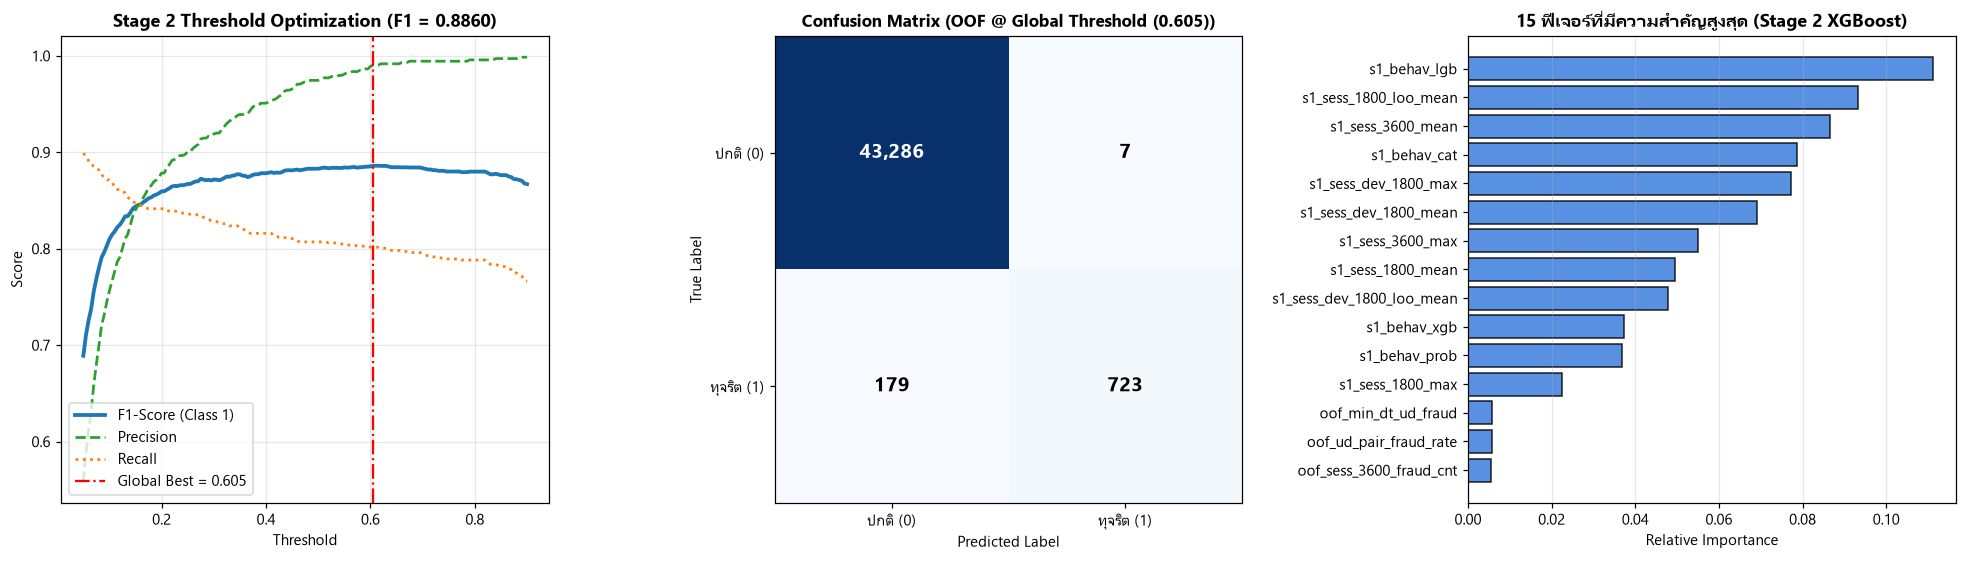

In [6]:
thresholds = np.linspace(0.05, 0.90, 171)
f1_list, prec_list, rec_list = [], [], []
for t in thresholds:
    pr = (oof_s2_blend >= t).astype(int)
    f1_list.append(f1_score(y_tr, pr))
    prec_list.append(precision_score(y_tr, pr, zero_division=0))
    rec_list.append(recall_score(y_tr, pr, zero_division=0))

best_global_idx = int(np.argmax(f1_list))
opt_th_global = float(thresholds[best_global_idx])
opt_f1_global = float(f1_list[best_global_idx])

# ค้นหา Regime-Aware Threshold แบบ Cross-Validated
cv_regime_preds = np.zeros(len(tr_indices), dtype=int)
th_obs_list, th_unobs_list = [], []

for fold, (fit_idx, val_idx) in enumerate(skf.split(tr_indices, y_tr)):
    fit_obs = oof_sess_obs_cnt[fit_idx] > 0

    best_t_o, best_f_o = opt_th_global, -1.0
    for t in np.linspace(0.20, 0.75, 56):
        f = f1_score(y_tr[fit_idx][fit_obs], (oof_s2_blend[fit_idx][fit_obs] >= t).astype(int))
        if f > best_f_o:
            best_f_o, best_t_o = f, t

    best_t_u, best_f_u = opt_th_global, -1.0
    for t in np.linspace(0.15, 0.65, 51):
        p_tmp = np.where(fit_obs, oof_s2_blend[fit_idx] >= best_t_o, oof_s2_blend[fit_idx] >= t).astype(int)
        f = f1_score(y_tr[fit_idx], p_tmp)
        if f > best_f_u:
            best_f_u, best_t_u = f, t

    th_obs_list.append(best_t_o)
    th_unobs_list.append(best_t_u)
    val_obs = oof_sess_obs_cnt[val_idx] > 0
    cv_regime_preds[val_idx] = np.where(val_obs, oof_s2_blend[val_idx] >= best_t_o, oof_s2_blend[val_idx] >= best_t_u).astype(int)

cv_regime_f1 = f1_score(y_tr, cv_regime_preds)
mean_th_obs = float(np.mean(th_obs_list))
mean_th_unobs = float(np.mean(th_unobs_list))

if cv_regime_f1 > opt_f1_global:
    use_regime = True
    final_oof_preds = cv_regime_preds
    final_oof_f1 = cv_regime_f1
    chosen_th_desc = f"Regime-Aware (obs>0: {mean_th_obs:.3f}, obs==0: {mean_th_unobs:.3f})"
else:
    use_regime = False
    final_oof_preds = (oof_s2_blend >= opt_th_global).astype(int)
    final_oof_f1 = opt_f1_global
    chosen_th_desc = f"Global Threshold ({opt_th_global:.3f})"

cm = confusion_matrix(y_tr, final_oof_preds)
tn, fp, fn, tp = cm.ravel()

m_unobs = oof_sess_obs_cnt == 0
rec_unobs = recall_score(y_tr[m_unobs], final_oof_preds[m_unobs])
prec_unobs = precision_score(y_tr[m_unobs], final_oof_preds[m_unobs], zero_division=0)
tp_unobs = int(((y_tr[m_unobs] == 1) & (final_oof_preds[m_unobs] == 1)).sum())
tot_unobs_f = int((y_tr[m_unobs] == 1).sum())

print(f"Global Best Threshold: {opt_th_global:.3f} -> OOF F1 = {opt_f1_global:.5f}")
print(f"Regime-Aware CV Threshold (obs>0: {mean_th_obs:.3f}, obs==0: {mean_th_unobs:.3f}) -> OOF F1 = {cv_regime_f1:.5f}")
print(f"เลือกใช้กลยุทธ์: {chosen_th_desc} (OOF F1 = {final_oof_f1:.5f})\n")
print("รายละเอียด Confusion Matrix บนชุดข้อมูล Train (44,195 รายการ):")
print(f"  - True Negative  (ทำนายปกติถูกต้อง):   {tn:,} รายการ")
print(f"  - False Positive (แจ้งเตือนเกินจริง):     {fp:,} รายการ")
print(f"  - False Negative (หลุดรอดการตรวจจับ): {fn:,} รายการ")
print(f"  - True Positive  (จับทุจริตได้ถูกต้อง):   {tp:,} รายการ")
print(f"  - กลุ่มไม่มีประวัติใน Session (obs==0): จับได้ {tp_unobs}/{tot_unobs_f} รายการ (Precision={prec_unobs:.4f}, Recall={rec_unobs:.4f})")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

axes[0].plot(thresholds, f1_list, label='F1-Score (Class 1)', color='#1f77b4', linewidth=2.5)
axes[0].plot(thresholds, prec_list, label='Precision', color='#2ca02c', linestyle='--', linewidth=1.8)
axes[0].plot(thresholds, rec_list, label='Recall', color='#ff7f0e', linestyle=':', linewidth=1.8)
axes[0].axvline(opt_th_global, color='red', linestyle='-.', linewidth=1.5, label=f'Global Best = {opt_th_global:.3f}')
axes[0].set_title(f'Stage 2 Threshold Optimization (F1 = {final_oof_f1:.4f})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Threshold')
axes[0].set_ylabel('Score')
axes[0].legend(loc='lower left')
axes[0].grid(True, alpha=0.3)

axes[1].imshow(cm, interpolation='nearest', cmap='Blues')
axes[1].set_title(f'Confusion Matrix (OOF @ {chosen_th_desc})', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')
axes[1].set_xticks([0, 1])
axes[1].set_yticks([0, 1])
axes[1].set_xticklabels(['ปกติ (0)', 'ทุจริต (1)'])
axes[1].set_yticklabels(['ปกติ (0)', 'ทุจริต (1)'])
for r_i in range(2):
    for c_i in range(2):
        color = 'white' if cm[r_i, c_i] > cm.max() / 2 else 'black'
        axes[1].text(c_i, r_i, f'{cm[r_i, c_i]:,}', ha='center', va='center', color=color, fontsize=13, fontweight='bold')

fi_series = pd.Series(feature_importances, index=all_s2_cols).sort_values(ascending=True).tail(15)
axes[2].barh(fi_series.index, fi_series.values, color='#3b7ddd', edgecolor='black', alpha=0.85)
axes[2].set_title('15 ฟีเจอร์ที่มีความสำคัญสูงสุด (Stage 2 XGBoost)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Relative Importance')
axes[2].grid(True, axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

### 7. การทำนายผลชุดข้อมูล Test และสร้างไฟล์ส่งคำตอบ (Submission Generation)
แปลงค่าความน่าจะเป็นที่ทำนายได้จาก Stage 2 AI Ensemble เป็น `0` หรือ `1` ด้วย Threshold ที่ดีที่สุด แล้วบันทึกเป็นไฟล์ `submission.csv`

In [7]:
if use_regime:
    test_obs_mask = test_sess_obs_cnt > 0
    test_pred_binary = np.where(test_obs_mask, test_s2_blend >= mean_th_obs, test_s2_blend >= mean_th_unobs).astype(int)
else:
    test_pred_binary = (test_s2_blend >= opt_th_global).astype(int)

pred_map = pd.Series(test_pred_binary, index=df.loc[te_mask, 'id'].values)

submission = pd.DataFrame({
    'id': test_df['id'].values,
    'is_fraud': test_df['id'].map(pred_map).astype(int).values
})
submission.to_csv('submission.csv', index=False)

n_fraud_pred = int(submission['is_fraud'].sum())
rate_fraud_pred = submission['is_fraud'].mean()

print("บันทึกไฟล์ 'submission.csv' เรียบร้อยแล้ว!")
print(f"จำนวนแถวทั้งหมดใน submission.csv: {len(submission):,} แถว")
print(f"จำนวนธุรกรรมที่ทำนายว่าเป็นทุจริต (is_fraud = 1): {n_fraud_pred:,} รายการ ({rate_fraud_pred:.4%})")
print(f"จำนวนธุรกรรมที่ทำนายว่าเป็นปกติ (is_fraud = 0):   {len(submission) - n_fraud_pred:,} รายการ ({1 - rate_fraud_pred:.4%})")

submission.head(10)

บันทึกไฟล์ 'submission.csv' เรียบร้อยแล้ว!
จำนวนแถวทั้งหมดใน submission.csv: 18,899 แถว
จำนวนธุรกรรมที่ทำนายว่าเป็นทุจริต (is_fraud = 1): 324 รายการ (1.7144%)
จำนวนธุรกรรมที่ทำนายว่าเป็นปกติ (is_fraud = 0):   18,575 รายการ (98.2856%)


,id,is_fraud
0,5928177,0
1,3515138,0
2,7294810,0
3,7592106,0
4,6981260,0
5,1699305,0
6,1109139,0
7,3453351,0
8,9605985,0
9,4543669,0
